Objectives: 

Write a script that loads the CSV and prints a summary report.

Acceptance criteria:

It shows the first date, the last date, and the number of rows.
For each currency, it shows the first and last date with a rate and the percentage of missing values.
It lists the currencies that were discontinued, meaning they have no rate in the last 30 days of the file.
It lists every gap of more than 4 calendar days between consecutive dates. Normal weekends shouldn't appear in that list. 

In [137]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 



df = pd.read_csv("https://www.ecb.europa.eu/stats/eurofxref/eurofxref-hist.zip")
df = df.fillna(0)
df['Date'] = pd.to_datetime(df['Date'])
df = df.drop('BGN',axis = 1)
df

,Date,USD,JPY,CYP,CZK,DKK,EEK,GBP,HUF,LTL,...,INR,KRW,MXN,MYR,NZD,PHP,SGD,THB,ZAR,Unnamed: 42
0,2026-10-23,1.1193,175.51,0.00000,24.327,7.4748,0.0000,0.83728,366.73,0.0000,...,106.2720,1482.46,21.0226,4.5729,1.9682,71.235,1.4310,37.771,18.5777,0.0
1,2026-10-22,1.1205,175.97,0.00000,24.260,7.4747,0.0000,0.83770,366.43,0.0000,...,106.2490,1484.25,21.0215,4.5756,1.9724,71.162,1.4315,37.811,18.5058,0.0
2,2026-10-21,1.1234,177.36,0.00000,24.262,7.4746,0.0000,0.83825,365.00,0.0000,...,106.1265,1489.15,20.7632,4.5843,1.9735,71.121,1.4348,37.718,18.3930,0.0
3,2026-10-20,1.1215,177.34,0.00000,24.329,7.4746,0.0000,0.84028,364.68,0.0000,...,106.4590,1489.17,20.7719,4.5788,1.9748,70.804,1.4338,37.738,18.4769,0.0
4,2026-10-19,1.1225,177.63,0.00000,24.343,7.4747,0.0000,0.84205,363.40,0.0000,...,106.5590,1492.35,20.7481,4.5826,1.9792,70.715,1.4357,37.665,18.4469,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7116,1999-01-08,1.1659,130.09,0.58187,34.938,7.4433,15.6466,0.70940,250.15,4.6643,...,0.0000,1366.73,0.0000,0.0000,2.1557,0.000,1.9537,0.000,6.7855,0.0
7117,1999-01-07,1.1632,129.43,0.58187,34.886,7.4431,15.6466,0.70585,250.09,4.6548,...,0.0000,1337.16,0.0000,0.0000,2.1531,0.000,1.9436,0.000,6.8283,0.0
7118,1999-01-06,1.1743,131.42,0.58200,34.850,7.4452,15.6466,0.70760,250.67,4.6994,...,0.0000,1359.54,0.0000,0.0000,2.1890,0.000,1.9699,0.000,6.7307,0.0
7119,1999-01-05,1.1790,130.96,0.58230,34.917,7.4495,15.6466,0.71220,250.80,4.7174,...,0.0000,1373.01,0.0000,0.0000,2.2011,0.000,1.9655,0.000,6.7975,0.0


In [138]:
df.describe()

,Date,USD,JPY,CYP,CZK,DKK,EEK,GBP,HUF,LTL,...,INR,KRW,MXN,MYR,NZD,PHP,SGD,THB,ZAR,Unnamed: 42
count,7121,7121.000000,7121.000000,7121.000000,7121.000000,7121.000000,7121.000000,7121.000000,7121.00000,7121.000000,...,7121.000000,7121.000000,7121.000000,7121.000000,7121.000000,7121.000000,7121.000000,7121.000000,7121.000000,7121.0
mean,2012-11-26 07:41:39.929785088,1.181597,132.908219,0.187127,27.653378,7.449817,6.754339,0.786676,302.48512,2.029579,...,51.078009,1375.311399,13.352424,3.581624,1.821254,46.604827,1.705263,31.510602,12.961906,0.0
min,1999-01-04 00:00:00,0.825200,89.300000,0.000000,22.968000,7.423400,0.000000,0.571100,228.16000,0.000000,...,0.000000,938.670000,0.000000,0.000000,1.388400,0.000000,1.383800,0.000000,6.078500,0.0
25%,2005-12-12 00:00:00,1.086400,119.770000,0.000000,25.208000,7.439800,0.000000,0.687300,257.07000,0.000000,...,0.000000,1260.860000,0.000000,3.969100,1.672600,51.244000,1.526800,34.709000,9.286700,0.0
50%,2012-11-21 00:00:00,1.167100,130.840000,0.000000,26.223000,7.450400,0.000000,0.834000,296.56000,3.452800,...,69.821800,1349.100000,17.497700,4.587000,1.786300,58.193000,1.620300,38.080000,12.555600,0.0
75%,2019-11-11 00:00:00,1.294400,141.470000,0.574250,28.990000,7.459500,15.646600,0.865550,331.92000,3.452800,...,82.580300,1472.840000,20.832100,4.780300,1.969000,62.168000,1.910200,41.715000,16.794100,0.0
max,2026-10-23 00:00:00,1.599000,187.720000,0.588800,38.583000,7.475900,15.646600,0.978550,430.65000,4.717400,...,112.317000,1993.950000,27.089600,5.185700,2.553500,72.815000,2.232300,53.536000,21.878800,0.0
std,NaN,0.150911,20.125343,0.270602,3.514956,0.011930,7.750470,0.096917,50.31536,1.751298,...,39.425839,168.846477,9.483433,1.946971,0.193568,25.486097,0.223082,17.402083,4.440149,0.0


In [139]:
df['Date'] = pd.to_datetime(df['Date']) 
print('first data: ',df['Date'].min())
print('current data :',df['Date'].max())

print('number of rows: ',df.shape[0])

print()

def data_quality_report(df):
    missing = df.isna().sum().sum()
    zero = (df == 0).sum().sum()
    total = df.size
    
    print("=== Data Quality Report ===")
    print(f"Total cells: {total}")
    print(f"Missing values: {missing}")
    print(f"Zero values: {zero}")
    print(f"Missing %: {missing/total*100:.2f}%")
    print(f"Zero %: {zero/total*100:.2f}%")

data_quality_report(df)

first data:  1999-01-04 00:00:00
current data : 2026-10-23 00:00:00
number of rows:  7121

=== Data Quality Report ===
Total cells: 299082
Missing values: 0
Zero values: 76919
Missing %: 0.00%
Zero %: 25.72%


In [140]:
data = df[:30]
currency_cols = [col for col in data.columns if col.strip().lower() != 'date']

zero_cols = []
empty_cols = []

for col in currency_cols:
    series = pd.to_numeric(data[col], errors='coerce')
    if (series == 0.0).all():
        zero_cols.append(col)
        print(f"Column '{col}' has 0.0 for all 30 days.")

    if series.isnull().all():
        empty_cols.append(col)
        print(f"Column '{col}' is completely empty (all NaN).")

Column 'CYP' has 0.0 for all 30 days.
Column 'EEK' has 0.0 for all 30 days.
Column 'LTL' has 0.0 for all 30 days.
Column 'LVL' has 0.0 for all 30 days.
Column 'MTL' has 0.0 for all 30 days.
Column 'ROL' has 0.0 for all 30 days.
Column 'SIT' has 0.0 for all 30 days.
Column 'SKK' has 0.0 for all 30 days.
Column 'HRK' has 0.0 for all 30 days.
Column 'RUB' has 0.0 for all 30 days.
Column 'TRL' has 0.0 for all 30 days.
Column 'Unnamed: 42' has 0.0 for all 30 days.


Ticket 2: Month-end rates for Treasury (Priority: high, about 1 day)

From Treasury: “Our month-end close needs EUR/GBP, EUR/USD and EUR/INR for the last 24 months.”

Acceptance criteria:

The month-end rate is the last published rate on or before the last calendar day of the month. If the 31st is a Sunday, use Friday’s rate.
The output is a CSV with the columns month_end, currency, rate, rate_date_used.
The rate_date_used column is mandatory, because auditors will ask which day’s rate you actually used.

In [141]:
filter_data = df[['Date','USD','GBP','INR']]
filter_data


,Date,USD,GBP,INR
0,2026-10-23,1.1193,0.83728,106.2720
1,2026-10-22,1.1205,0.83770,106.2490
2,2026-10-21,1.1234,0.83825,106.1265
3,2026-10-20,1.1215,0.84028,106.4590
4,2026-10-19,1.1225,0.84205,106.5590
...,...,...,...,...
7116,1999-01-08,1.1659,0.70940,0.0000
7117,1999-01-07,1.1632,0.70585,0.0000
7118,1999-01-06,1.1743,0.70760,0.0000
7119,1999-01-05,1.1790,0.71220,0.0000


In [142]:
filter_data['Date'] = pd.to_datetime(filter_data['Date'])   
filter_data["Year_Month"] = filter_data["Date"].dt.to_period("M")
month_ends = filter_data.groupby("Year_Month").last().reset_index()
month_ends = month_ends[['Year_Month', 'USD', 'GBP', 'INR']]
month_ends = month_ends.tail(24)
month_ends




C:\Users\somil\AppData\Local\Temp\ipykernel_5080\2850240388.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filter_data['Date'] = pd.to_datetime(filter_data['Date'])
C:\Users\somil\AppData\Local\Temp\ipykernel_5080\2850240388.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filter_data["Year_Month"] = filter_data["Date"].dt.to_period("M")


,Year_Month,USD,GBP,INR
310,2024-11,1.0885,0.83998,91.4955
311,2024-12,1.0507,0.82898,89.0010
312,2025-01,1.0321,0.83118,88.5070
313,2025-02,1.0274,0.83136,89.4513
314,2025-03,1.0465,0.82530,91.3530
315,2025-04,1.0788,0.83665,92.3840
316,2025-05,1.1343,0.85330,95.6221
317,2025-06,1.1419,0.84340,97.4995
318,2025-07,1.1810,0.85880,101.0525
319,2025-08,1.1404,0.86650,99.7900


Currency Converter 

In [143]:
current_value = (df[['Date', 'GBP','INR']]).head(1)
print("Current value of GBP and INR: ")
print(current_value)


Current value of GBP and INR: 
        Date      GBP      INR
0 2026-10-23  0.83728  106.272


In [144]:
def convert_currency():
    amount_gbp = 150.00
    in_inr = amount_gbp * current_value['INR'] / current_value['GBP']
    return in_inr

print(convert_currency())
  

0    19038.79228
dtype: float64


In [ ]:
from datetime import datetime

def specific_date(df):
    # User input
    specific_date = input("Enter the date (YYYY-MM-DD): ")
    specific_currency = input("Enter the currency (e.g., GBP): ").upper()

    # Convert string → datetime.date
    try:
        d = datetime.strptime(specific_date, "%Y-%m-%d").date()
    except ValueError:
        print("Invalid date format. Use YYYY-MM-DD.")
        return

    # Check if date exists in the DataFrame
    if d  in df['Date'].values:
        print(f"Rates on this day : {d}")
    else:
        print('No rates Available for this day')
        return

    # Filter the row for that date
    row = df[df['Date'] == d].iloc[0]

    # Check if currency exists
    if specific_currency not in row.index:
        print(f"No rate available for {specific_currency} on {d}")
        return

    # Print the rate
    print(f"Rate for {specific_currency} on {d}: {row[specific_currency]}")


In [145]:
import pandas as pd 

invoice_data = pd.read_excel(r"C:\Users\somil\Downloads\Project excel file.xlsx")
invoice_data.to_csv(r"C:\Users\somil\Downloads\Project excel file.csv", index = False)

invoice_data

,invoice_id,client,currency,amount,invoice_date,payment_date
0,INV‑101,Thames Capital,GBP,250000,2025‑01‑15,2025‑03‑14
1,INV‑102,Hudson Partners,USD,1200000,2025‑02‑03,2025‑04‑30
2,INV‑103,Mumbai Growth Fund,INR,85000000,2025‑03‑10,2025‑06‑02
3,INV‑104,Gulf Holdings,AED,3000000,2025‑04‑01,2025‑05‑29
4,INV‑105,Hudson Partners,USD,450000,2025‑05‑20,2025‑05‑25
5,INV‑106,Thames Capital,GBP,180000,2025‑06‑30,2025‑09‑30


In [146]:
df.columns

Index(['Date', 'USD', 'JPY', 'CYP', 'CZK', 'DKK', 'EEK', 'GBP', 'HUF', 'LTL',
       'LVL', 'MTL', 'PLN', 'ROL', 'RON', 'SEK', 'SIT', 'SKK', 'CHF', 'ISK',
       'NOK', 'HRK', 'RUB', 'TRL', 'TRY', 'AUD', 'BRL', 'CAD', 'CNY', 'HKD',
       'IDR', 'ILS', 'INR', 'KRW', 'MXN', 'MYR', 'NZD', 'PHP', 'SGD', 'THB',
       'ZAR', 'Unnamed: 42'],
      dtype='object')

In [147]:
invoice_data = pd.read_excel(r"C:\Users\somil\Downloads\Project excel file.xlsx")
invoice_data.to_csv(r"C:\Users\somil\Downloads\Project excel file.csv", index = False)
print(invoice_data)

df['AED'] = df['USD']*3.6725
lst = invoice_data[['currency','amount','invoice_date','payment_date']]

for idx,row in lst.iterrows():
    ccy = row['currency']
    inv_date = pd.to_datetime(str(row['invoice_date']).replace('\u2011', '-'))
    pay_date = pd.to_datetime(str(row['payment_date']).replace('\u2011', '-'))
    pay_date = pd.to_datetime(str(row['payment_date']).replace('\u2011', '-'))
    if ccy in df.columns:
        # Fetch the rate on or immediately before the date (handling weekends/holidays)
        booking_rows = df.loc[
            (df["Date"] <= inv_date) & df[ccy].notna() & (df[ccy] != 0)
        ].sort_values("Date", ascending=False)

        payment_rows = df.loc[
            (df["Date"] <= pay_date) & df[ccy].notna() & (df[ccy] != 0)
        ].sort_values("Date", ascending=False)

        if booking_rows.empty or payment_rows.empty:
            print(f"--- Invoice {idx} ({ccy}) ---")
            print("  Warning: No rate available on or before the invoice or payment date.")
            continue

        booking_rate = booking_rows.iloc[0][ccy]
        payment_rate = payment_rows.iloc[0][ccy]
        payment_rate = payment_rows.iloc[0][ccy]

        print(f"--- Invoice {idx} ({ccy}) ---")
        print(
            f"  Invoice Date: {inv_date.strftime('%Y-%m-%d')} | EUR Rate: {booking_rate}"
        )
        print(
            f"  Payment Date: {pay_date.strftime('%Y-%m-%d')} | EUR Rate: {payment_rate}"
        )
        print(
            f"Gain/Loss: {row['amount'] * (payment_rate - booking_rate):.2f} EUR"
        )

    else:
        print(f"--- Invoice {idx} ({ccy}) ---")
        print(f"  Warning: Currency '{ccy}' is not quoted in the ECB dataset!")


  invoice_id              client currency    amount invoice_date payment_date
0    INV‑101      Thames Capital      GBP    250000   2025‑01‑15   2025‑03‑14
1    INV‑102     Hudson Partners      USD   1200000   2025‑02‑03   2025‑04‑30
2    INV‑103  Mumbai Growth Fund      INR  85000000   2025‑03‑10   2025‑06‑02
3    INV‑104       Gulf Holdings      AED   3000000   2025‑04‑01   2025‑05‑29
4    INV‑105     Hudson Partners      USD    450000   2025‑05‑20   2025‑05‑25
5    INV‑106      Thames Capital      GBP    180000   2025‑06‑30   2025‑09‑30
--- Invoice 0 (GBP) ---
  Invoice Date: 2025-01-15 | EUR Rate: 0.84313
  Payment Date: 2025-03-14 | EUR Rate: 0.84183
Gain/Loss: -325.00 EUR
--- Invoice 1 (USD) ---
  Invoice Date: 2025-02-03 | EUR Rate: 1.0274
  Payment Date: 2025-04-30 | EUR Rate: 1.1373
Gain/Loss: 131880.00 EUR
--- Invoice 2 (INR) ---
  Invoice Date: 2025-03-10 | EUR Rate: 94.6938
  Payment Date: 2025-06-02 | EUR Rate: 97.4995
Gain/Loss: 238484500.00 EUR
--- Invoice 3 (AED) ---
  

In [148]:
invoice_data = pd.read_excel(r"C:\Users\somil\Downloads\Project excel file.xlsx")
invoice_data.to_csv(r"C:\Users\somil\Downloads\Project excel file.csv", index=False)
print(invoice_data)

# Synthesize AED peg from USD
df["AED"] = df["USD"] * 3.6725
lst = invoice_data[["currency", "amount", "invoice_date", "payment_date"]]

# Tracking totals for portfolio summary
total_eur_booked = 0.0
total_eur_paid = 0.0
currency_pnl = {}

for idx, row in lst.iterrows():
    ccy = str(row["currency"]).strip()
    amt = float(row["amount"])
    inv_date = pd.to_datetime(str(row["invoice_date"]).replace("\u2011", "-"))
    pay_date = pd.to_datetime(str(row["payment_date"]).replace("\u2011", "-"))

    if ccy in df.columns:
        # Fetch the rate on or immediately before the date
        booking_rows = df.loc[
            (df["Date"] <= inv_date) & df[ccy].notna() & (df[ccy] != 0)
        ].sort_values("Date", ascending=False)

        payment_rows = df.loc[
            (df["Date"] <= pay_date) & df[ccy].notna() & (df[ccy] != 0)
        ].sort_values("Date", ascending=False)

        if booking_rows.empty or payment_rows.empty:
            print(f"--- Invoice {idx} ({ccy}) ---")
            print("  Warning: No rate available on or before the invoice or payment date.\n")
            continue

        booking_rate = float(booking_rows.iloc[0][ccy])
        payment_rate = float(payment_rows.iloc[0][ccy])
        actual_inv_date = booking_rows.iloc[0]["Date"].strftime("%Y-%m-%d")
        actual_pay_date = payment_rows.iloc[0]["Date"].strftime("%Y-%m-%d")

        # Valuation calculations
        eur_booked = amt / booking_rate
        eur_paid = amt / payment_rate
        gain_loss = eur_paid - eur_booked

        # Update totals
        total_eur_booked += eur_booked
        total_eur_paid += eur_paid
        currency_pnl[ccy] = currency_pnl.get(ccy, 0.0) + gain_loss

        # Label outcome
        outcome = "Gain" if gain_loss >= 0 else "Loss"

        print(f"--- Invoice {idx} ({ccy}) ---")
        print(f"  Amount: {amt:,.2f} {ccy}")
        print(f"  Invoice Date: {inv_date.strftime('%Y-%m-%d')} (Rate Date: {actual_inv_date}) | Rate: {booking_rate:.4f} | Booked: €{eur_booked:,.2f}")
        print(f"  Payment Date: {pay_date.strftime('%Y-%m-%d')} (Rate Date: {actual_pay_date}) | Rate: {payment_rate:.4f} | Paid: €{eur_paid:,.2f}")
        print(f"  FX {outcome}: €{abs(gain_loss):,.2f} (Net: €{gain_loss:+,.2f})\n")

    else:
        print(f"--- Invoice {idx} ({ccy}) ---")
        print(f"  Warning: Currency '{ccy}' is not quoted in the ECB dataset!\n")

# Portfolio-wide summary
total_net_pnl = total_eur_paid - total_eur_booked
print("=" * 60)
print("PORTFOLIO SUMMARY")
print("=" * 60)
print(f"Total EUR Booked : €{total_eur_booked:,.2f}")
print(f"Total EUR Paid   : €{total_eur_paid:,.2f}")
print(f"Net FX Gain/Loss : €{total_net_pnl:+,.2f}")
print("-" * 60)
print("Breakdown by Currency:")
for c, pnl in currency_pnl.items():
    print(f"  * {c}: €{pnl:+,.2f}")
print("=" * 60)

  invoice_id              client currency    amount invoice_date payment_date
0    INV‑101      Thames Capital      GBP    250000   2025‑01‑15   2025‑03‑14
1    INV‑102     Hudson Partners      USD   1200000   2025‑02‑03   2025‑04‑30
2    INV‑103  Mumbai Growth Fund      INR  85000000   2025‑03‑10   2025‑06‑02
3    INV‑104       Gulf Holdings      AED   3000000   2025‑04‑01   2025‑05‑29
4    INV‑105     Hudson Partners      USD    450000   2025‑05‑20   2025‑05‑25
5    INV‑106      Thames Capital      GBP    180000   2025‑06‑30   2025‑09‑30
--- Invoice 0 (GBP) ---
  Amount: 250,000.00 GBP
  Invoice Date: 2025-01-15 (Rate Date: 2025-01-15) | Rate: 0.8431 | Booked: €296,514.18
  Payment Date: 2025-03-14 (Rate Date: 2025-03-14) | Rate: 0.8418 | Paid: €296,972.07
  FX Gain: €457.89 (Net: €+457.89)

--- Invoice 1 (USD) ---
  Amount: 1,200,000.00 USD
  Invoice Date: 2025-02-03 (Rate Date: 2025-02-03) | Rate: 1.0274 | Booked: €1,167,996.89
  Payment Date: 2025-04-30 (Rate Date: 2025-04-30) | R

Daily Logs 

TOTAL FLAGGED JUMPY DAYS (> 3 Rolling Std): 110
         Date currency       rate  log_return  rolling_std_30d  \
0  2026-10-12      INR  107.08600   -0.012164         0.003748   
1  2026-06-18      USD    1.14610   -0.011279         0.003313   
2  2026-02-05      GBP    0.86910    0.008667         0.002732   
3  2026-02-03      INR  106.37100   -0.019052         0.005876   
4  2025-08-04      INR  101.37450    0.015754         0.004822   
5  2025-04-11      USD    1.13460    0.023543         0.007780   
6  2025-04-03      INR   94.63250    0.024285         0.006340   
7  2025-04-03      USD    1.10970    0.026851         0.006464   
8  2025-03-05      GBP    0.83500    0.008564         0.002798   
9  2024-11-06      INR   90.18100   -0.016229         0.004223   
10 2024-11-06      USD    1.06950   -0.018711         0.004477   
11 2024-10-03      GBP    0.84258    0.011579         0.003113   
12 2024-08-05      USD    1.09660    0.012018         0.003139   
13 2024-08-05      GBP    0.

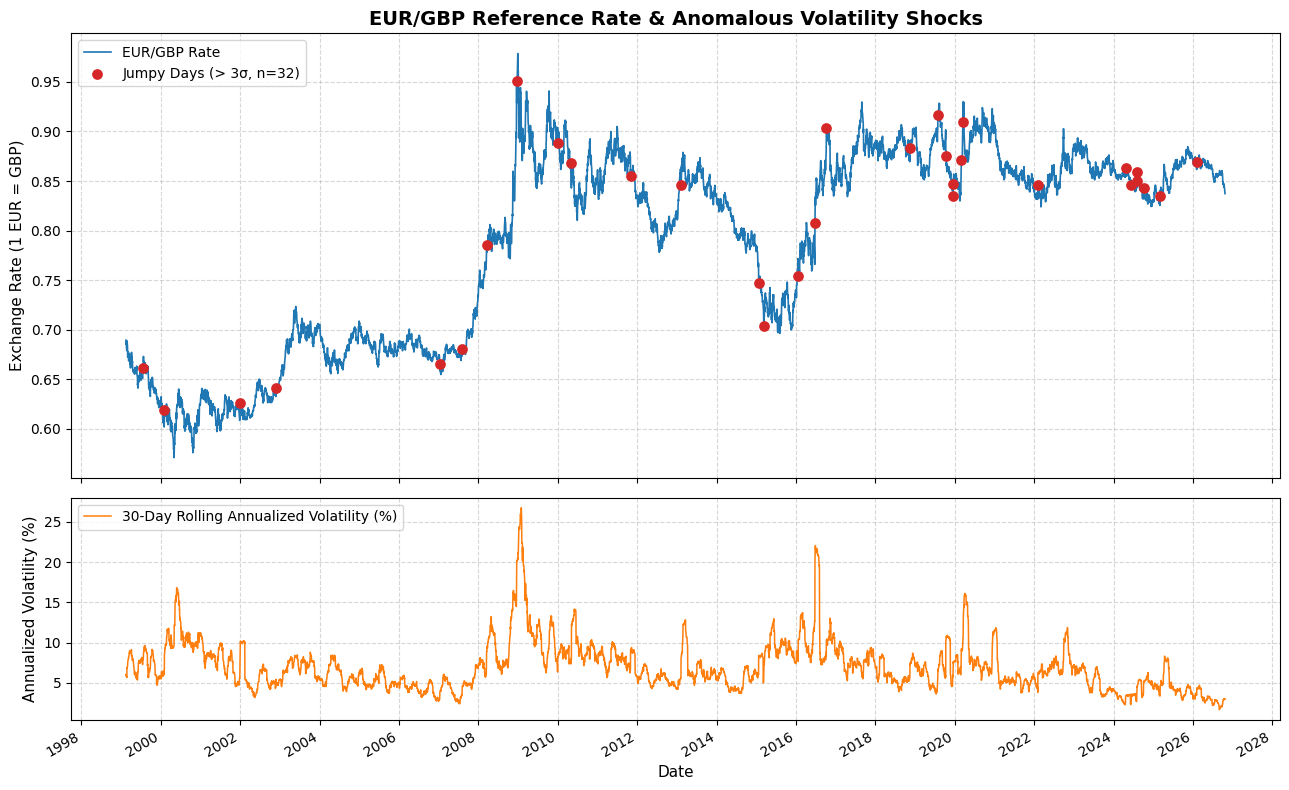

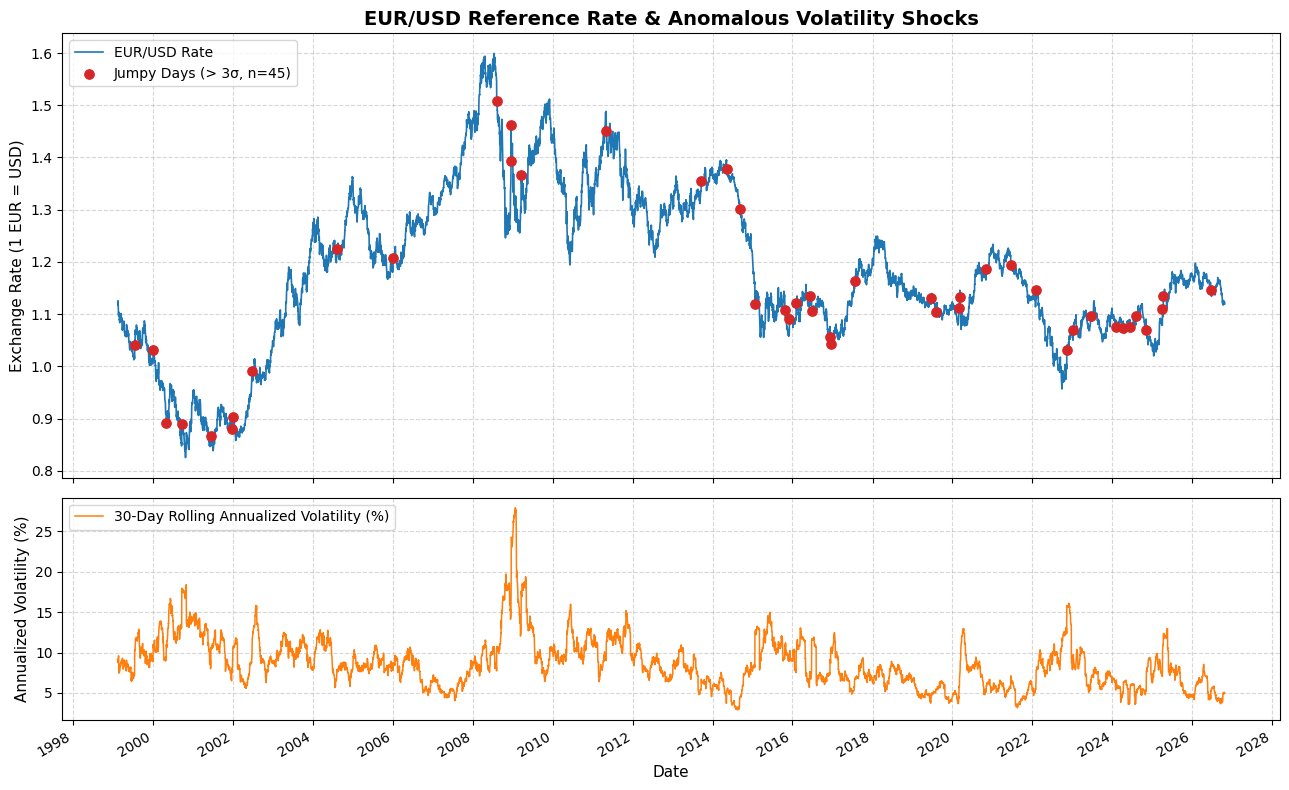

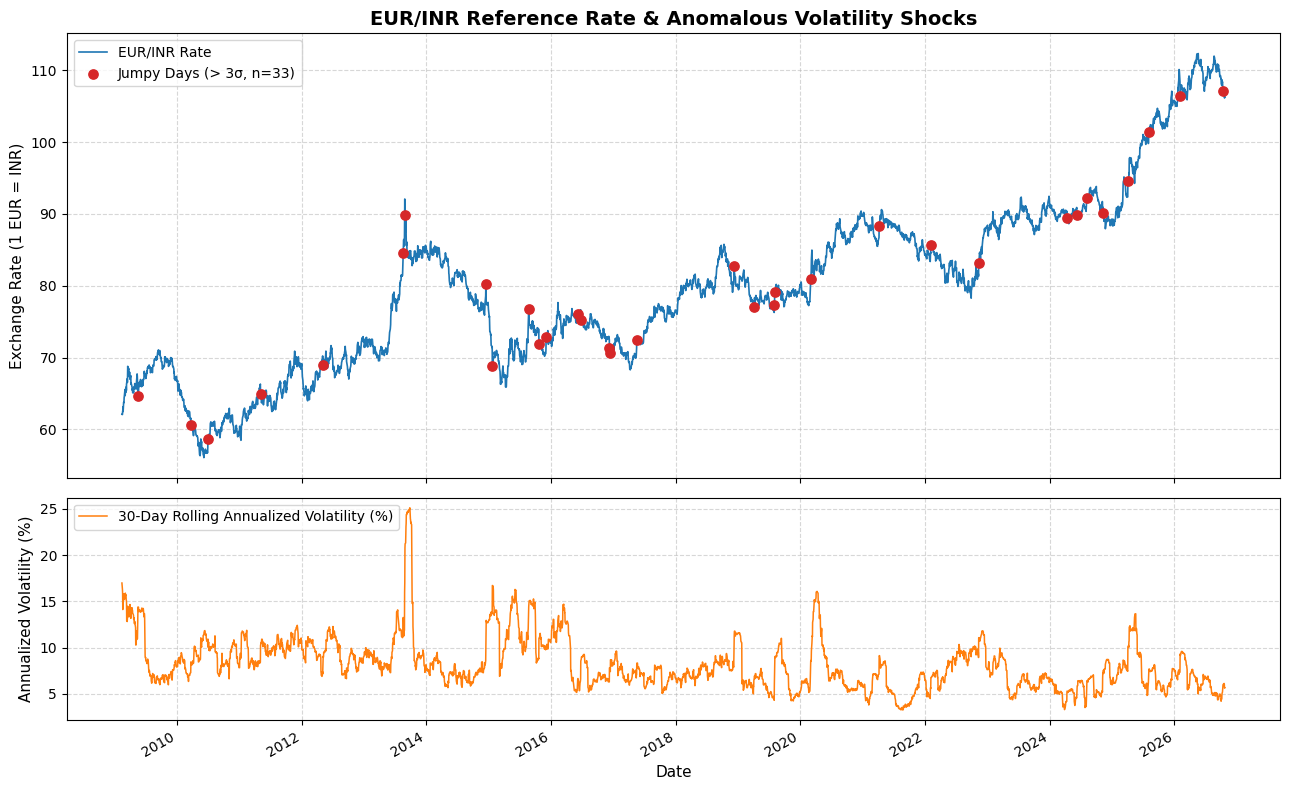

In [149]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# -------------------------------------------------------------------
# 1. Load Data & Clean
# -------------------------------------------------------------------
URL = "https://www.ecb.europa.eu/stats/eurofxref/eurofxref-hist.zip"
df = pd.read_csv(URL, compression="zip", na_values=["N/A", " "])
df.columns = df.columns.str.strip()
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

currencies = ["GBP", "USD", "INR"]
for c in currencies:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df_risk = df[["Date"] + currencies].copy()

# -------------------------------------------------------------------
# 2. Daily Log Returns, 30D Rolling Volatility & Shock Flags
# -------------------------------------------------------------------
flagged_list = []

for c in currencies:
    # Daily log return: r_t = ln(S_t / S_{t-1})
    df_risk[f"{c}_log_ret"] = np.log(df_risk[c] / df_risk[c].shift(1))

    # 30-day rolling standard deviation of daily log returns
    df_risk[f"{c}_rolling_std"] = (
        df_risk[f"{c}_log_ret"].rolling(window=30).std()
    )

    # 30-day rolling annualized volatility = std * sqrt(252)
    df_risk[f"{c}_vol_ann"] = df_risk[f"{c}_rolling_std"] * np.sqrt(252)

    # Flag days where absolute move exceeds 3 rolling standard deviations
    threshold = 3.0 * df_risk[f"{c}_rolling_std"]
    df_risk[f"{c}_flag"] = df_risk[f"{c}_log_ret"].abs() > threshold

    # Collect flagged records
    c_flags = df_risk[df_risk[f"{c}_flag"]][
        ["Date", c, f"{c}_log_ret", f"{c}_rolling_std", f"{c}_vol_ann"]
    ].copy()
    c_flags["currency"] = c
    c_flags = c_flags.rename(
        columns={
            c: "rate",
            f"{c}_log_ret": "log_return",
            f"{c}_rolling_std": "rolling_std_30d",
            f"{c}_vol_ann": "annualized_vol_30d",
        }
    )
    c_flags["z_score"] = (
        c_flags["log_return"].abs() / c_flags["rolling_std_30d"]
    )
    flagged_list.append(c_flags)

# Master Table of all flagged days across currencies
flagged_table = (
    pd.concat(flagged_list, ignore_index=True)
    .sort_values(by="Date", ascending=False)
    .reset_index(drop=True)
)

print("=" * 80)
print(f"TOTAL FLAGGED JUMPY DAYS (> 3 Rolling Std): {len(flagged_table)}")
print("=" * 80)
print(
    flagged_table[
        [
            "Date",
            "currency",
            "rate",
            "log_return",
            "rolling_std_30d",
            "annualized_vol_30d",
            "z_score",
        ]
    ].head(15)
)

# -------------------------------------------------------------------
# 3. Single Biggest Move in the Entire History
# -------------------------------------------------------------------
# Sort by absolute log return size
biggest_move = flagged_table.loc[flagged_table["log_return"].abs().idxmax()]

print("\n" + "=" * 80)
print("SINGLE BIGGEST FLAGGED MOVE IN HISTORY")
print("=" * 80)
print(f"Currency       : {biggest_move['currency']}")
print(f"Date           : {biggest_move['Date'].strftime('%Y-%m-%d (%A)')}")
print(f"Rate Published : {biggest_move['rate']}")
print(f"Log Return     : {biggest_move['log_return']:+.4%}")
print(f"Z-Score        : {biggest_move['z_score']:.2f} standard deviations")
print(
    f"30D Ann. Vol   : {biggest_move['annualized_vol_30d']:.2%} (annualized)"
)
print("=" * 80)

# -------------------------------------------------------------------
# 4. Visualization: One Chart Per Currency
# -------------------------------------------------------------------
for c in currencies:
    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1]}
    )

    valid_data = df_risk.dropna(subset=[f"{c}_rolling_std"]).copy()
    flags = valid_data[valid_data[f"{c}_flag"]]

    # Top Plot: Exchange Rate & Shock Points
    ax1.plot(
        valid_data["Date"],
        valid_data[c],
        color="#1f77b4",
        linewidth=1.2,
        label=f"EUR/{c} Rate",
    )
    ax1.scatter(
        flags["Date"],
        flags[c],
        color="#d62728",
        s=45,
        zorder=5,
        label=f"Jumpy Days (> 3σ, n={len(flags)})",
    )
    ax1.set_title(
        f"EUR/{c} Reference Rate & Anomalous Volatility Shocks",
        fontsize=14,
        fontweight="bold",
    )
    ax1.set_ylabel(f"Exchange Rate (1 EUR = {c})", fontsize=11)
    ax1.grid(True, linestyle="--", alpha=0.5)
    ax1.legend(loc="upper left")

    # Bottom Plot: 30-Day Rolling Annualized Volatility
    ax2.plot(
        valid_data["Date"],
        valid_data[f"{c}_vol_ann"] * 100,
        color="#ff7f0e",
        linewidth=1.1,
        label="30-Day Rolling Annualized Volatility (%)",
    )
    ax2.set_ylabel("Annualized Volatility (%)", fontsize=11)
    ax2.set_xlabel("Date", fontsize=11)
    ax2.grid(True, linestyle="--", alpha=0.5)
    ax2.legend(loc="upper left")

    ax1.xaxis.set_major_locator(mdates.YearLocator(2))
    ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.savefig(f"volatility_report_{c}.png", dpi=300)
    plt.show()

I want an email-style alert, not a dashboard I have to remember to check.


Compare the latest rate for each currency with its 30-day average

CheckWrite an alert to alerts.log when the difference is more than 2%

CheckUse the logging module, not print

CheckKeep thresholds in a config or .env file, not in the code

CheckMake it idempotent: run it twice on the same day and confirm there are no duplicate alerts



In [ ]:
import configparser
import json
import logging
from pathlib import Path
import numpy as np
import pandas as pd


CONFIG_PATH = Path("C:\\Users\\somil\\Downloads\\[ECB].ini")
config = configparser.ConfigParser()

if not CONFIG_PATH.exists():
    raise FileNotFoundError(
        f"Missing configuration file at {CONFIG_PATH.resolve()}"
    )

config.read(CONFIG_PATH)

ECB_URL = config.get(
    "ECB",
    "DATA_URL",
    fallback="https://www.ecb.europa.eu/stats/eurofxref/eurofxref-hist.zip",
)
TARGET_CURRENCIES = [
    c.strip()
    for c in config.get("ECB", "TARGET_CURRENCIES", fallback="GBP,USD,INR").split(
        ","
    )
]
WINDOW_DAYS = config.getint("ALERT_RULES", "WINDOW_DAYS", fallback=30)
THRESHOLD_PCT = config.getfloat("ALERT_RULES", "THRESHOLD_PCT", fallback=0.02)

LOG_FILE = config.get("STORAGE", "LOG_FILE", fallback="alerts.log")
STATE_FILE = Path(
    config.get("STORAGE", "STATE_FILE", fallback="alert_state.json")
)

# Configure the standard logging module
logging.basicConfig(
    filename=LOG_FILE,
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s",
    datefmt="%Y-%m-%d %H:%M:%S",
)
logger = logging.getLogger("RateAlert")


def load_state() -> dict:
    """Loads previously recorded alerts to prevent duplicates."""
    if STATE_FILE.exists():
        try:
            with open(STATE_FILE, "r") as f:
                return json.load(f)
        except Exception as e:
            logger.warning(
                f"Failed to read {STATE_FILE}, initializing clean state: {e}"
            )
            return {}
    return {}


def save_state(state: dict) -> None:
    """Persists alert state safely to disk."""
    with open(STATE_FILE, "w") as f:
        json.dump(state, f, indent=2)


def run_daily_rate_alert() -> None:
    # 1. Fetch ECB historical data
    df = pd.read_csv(ECB_URL, compression="zip", na_values=["N/A", " "])
    df.columns = df.columns.str.strip()
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").reset_index(drop=True)


    state = load_state()


    latest_date_dt = df["Date"].max()
    latest_date_str = latest_date_dt.strftime("%Y-%m-%d")

    
    logged_currencies_today = state.get(latest_date_str, [])

    
    for ccy in TARGET_CURRENCIES:
        if ccy not in df.columns:
            logger.warning(f"Currency '{ccy}' not found in ECB published dataset.")
            continue

        # Clean numeric series
        series = pd.to_numeric(df[ccy], errors="coerce").dropna()
        if len(series) < WINDOW_DAYS:
            logger.warning(
                f"Insufficient historical data for {ccy} (needs {WINDOW_DAYS} records)."
            )
            continue

        # Latest rate and trailing 30-day moving average
        latest_rate = float(series.iloc[-1])
        # Trailing 30 trading days including the latest rate
        rolling_30d_avg = float(series.iloc[-WINDOW_DAYS:].mean())

        # Percentage deviation: (Latest - Average) / Average
        pct_diff = (latest_rate - rolling_30d_avg) / rolling_30d_avg

        # 4. Check trigger condition (> 2% deviation in either direction)
        if abs(pct_diff) > THRESHOLD_PCT:
            # Idempotency Check: Don't log if already alerted for this date & currency
            if ccy in logged_currencies_today:
                # Already alerted today: skip silently to preserve idempotency
                continue

            direction = "ABOVE" if pct_diff > 0 else "BELOW"
            alert_message = (
                f"ALERT [Rate Date: {latest_date_str}]: EUR/{ccy} is {abs(pct_diff):.2%} {direction} "
                f"its {WINDOW_DAYS}-day average. Latest: {latest_rate:.4f} | "
                f"{WINDOW_DAYS}D Avg: {rolling_30d_avg:.4f} | Threshold: {THRESHOLD_PCT:.1%}"
            )

            # Write formatted alert to alerts.log
            logger.warning(alert_message)

            # Mark as dispatched in the state
            logged_currencies_today.append(ccy)

    # Update state persistence
    state[latest_date_str] = logged_currencies_today
    save_state(state)


if __name__ == "__main__":
    run_daily_rate_alert()
